# Import Packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using HypothesisTests
using LaTeXStrings
using Trapz



In [2]:
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Load Posteriors

In [10]:
poster = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try2.csv", DataFrame))

poster_red = poster[:,vcat(3:11, 16)];

In [4]:
using CairoMakie
using PairPlots
using DataFrames

# LDH Activity Assay

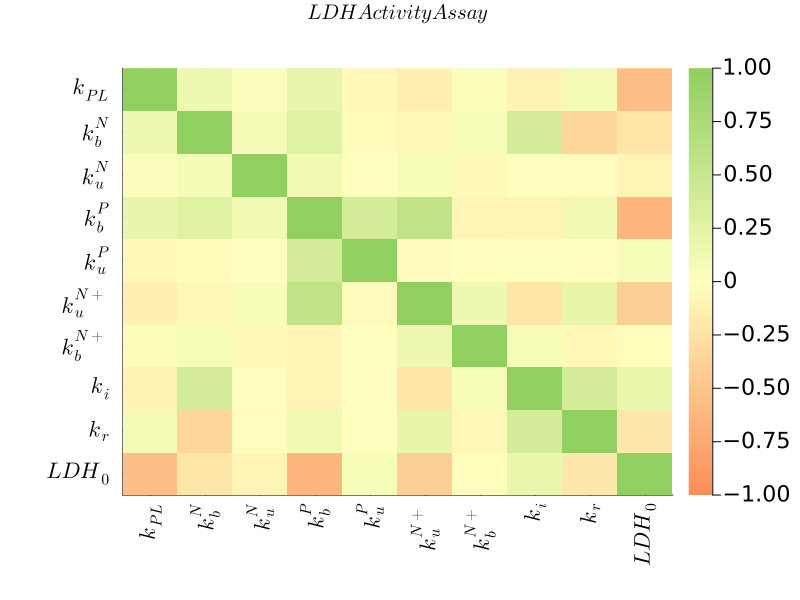

In [11]:
label =  [L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"LDH_0"]

pp = Plots.heatmap(cor(poster_red), 
        size = (800,600), margins=10Plots.mm,
        ticks = (1:10, label), xrotation = 90, c = :RdYlGn_3, clim = (-1,1), yflip=true, title = L"LDH Activity Assay", tickfontsize=15)
save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig31Stuff\\Covariance_LDHAss.svg", pp)
pp

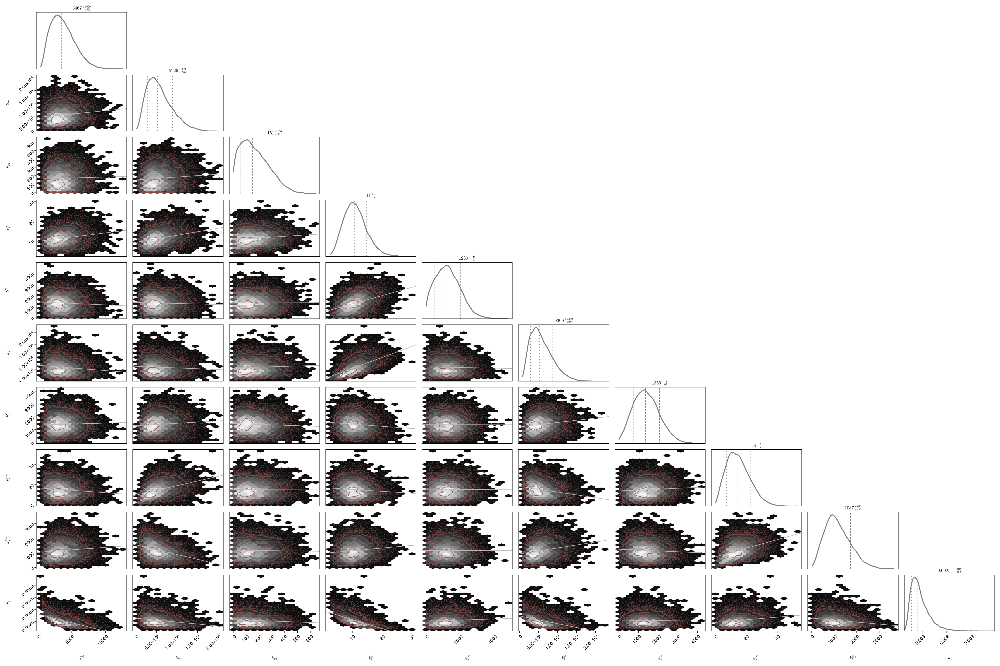

In [12]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"]

df = DataFrame(poster_red, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

# save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_InitialExperiment.svg", fig)

fig